# RGB+ELA U-Net JPEG 품질 증강 실험

- 작성자: kimjihwan
- 상태: **작성 중**
- 작성일: 2026-11-24
- 관련 작업: T14 JPEG 증강
- [보고서](../../docs/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug.md) · 비교 기준: [004 RGB+ELA U-Net](../../docs/rgb_ela_unet/EXP_kimjihwan_004_rgb_ela_unet_baseline.md) · 규약: [전처리 안내](../../docs/preprocessing.md) · [체크포인트 보관](../../docs/workflow.md#학습-체크포인트-보관)

## 목적·가설

002~004의 세 U-Net은 AutoSplice JPEG100에서 높았지만 JPEG90·75와 CocoGlide에서 크게 떨어졌음. 학습 조작본(JPEG100)은 마스크 밖이 Q75 원본을 Q100으로 다시 저장한 영역이고 마스크 안은 Q100으로 한 번 저장된 영역이라, 모델이 이 압축 이력 차이를 단서로 쓴 것으로 의심함(가설, 006 EDA에서 직접 측정). 제안서 4-3대로 val F1이 가장 높았던 RGB+ELA 입력에 JPEG 품질 증강(70~100)을 넣고 004와 같은 학습 예산으로 학습해, 품질별 하락 폭이 줄어드는지 확인함.

## 004에서 바꾼 점

- **JPEG 증강(유일한 학습 조건 변경):** 학습 샘플마다 원본 전체를 무작위 품질 q(70~100 정수, 균등)와 4:2:0으로 메모리에서 다시 저장한 뒤 ELA(quality 90, scale 15, subsampling 2)를 계산하고, 16의 배수 좌표로 256 크롭과 좌우반전을 적용함. 팀 규약(원본 전체 ELA → 크롭 → 반전)의 앞에 재저장 한 단계를 더한 순서임. 마스크는 바꾸지 않음. 모든 샘플에 적용함(q=100도 한 번 더 저장됨).
- **난수:** q·크롭 위치·반전은 `(시드, epoch, 샘플 번호)`로 정한 난수로 뽑아, 작업자 수나 재시작과 관계없이 같은 값이 나옴. 데이터 순서는 epoch마다 `시드×1000+epoch`로 섞음. 004와 난수 흐름이 달라 같은 크롭이 나오지는 않음.
- **선택 기준:** epoch마다 val 조작 F1을 JPEG100·90·75에서 모두 구함. 대표 결과는 세 품질 평균 F1 최고 epoch(`best_mean`), 기준 통일 확인용으로 JPEG100 F1 최고 epoch(`best_q100`, 004와 같은 기준)도 따로 저장해 둘 다 테스트함. 조기 종료는 평균 F1 기준임(최대 30 epoch, patience 5).
- **CocoGlide:** PNG를 JPEG 100·90·75(4:4:4)로 변환해 평가함(제안서 요구). 004 모델도 같은 CocoGlide 90·75로 평가함.
- **재시작:** 매 epoch 끝에 `last.pt`(모델·옵티마이저·기록)를 개인 Drive 폴더에 저장함. 세션이 끊기면 학습 셀만 다시 실행해 이어서 학습함.
- 나머지(모델, conv1 초기화, 정규화, `bce_dice`, Adam 1e-4, 배치 16, 조작본만 학습, 시드 42, 평가 규칙)는 004와 같음.

팀원이 VS Code의 Colab 원격 커널(GPU)에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함. 학습(7번 셀)과 테스트(9~11번 셀)는 각각 따로 실행·재실행할 수 있음.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/`와 `AI_Forensics/project/scripts/`를 읽음. 학습 기록·재시작 파일은 개인 폴더 `MyDrive/AI_Forensics_runs/kimjihwan/`에 저장하고, 대표 최선 체크포인트는 팀 규칙대로 공유 Drive `AI_Forensics/project/models/checkpoints/rgb_ela_unet/`에 자동 보관함. 데이터·가중치는 Git에 올리지 않음.

In [1]:
from pathlib import Path
from google.colab import drive
from io import BytesIO
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import random
import shutil
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
experiment_name = "EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug"
run_root = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan") / experiment_name
local_ckpt_root = work_root / "checkpoints" / experiment_name
shared_ckpt_path = project_root / "models/checkpoints/rgb_ela_unet" / f"{experiment_name}_best.pt"
ref004_dir = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_004_rgb_ela_unet_baseline/bce_dice")
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, make_ela, pad_image, unpad_image
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CUDA:", torch.version.cuda, "/ cuDNN:", torch.backends.cudnn.version())
print("TF32 matmul / cuDNN:", torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
print("CPU 코어:", os.cpu_count())
print("장치:", device)
if device.type != "cuda":
    raise RuntimeError("GPU 런타임에서 실행해야 함.")
properties = torch.cuda.get_device_properties(0)
print("GPU:", properties.name, f"{properties.total_memory / 1024**3:.1f} GiB")
print("실행 기록 폴더:", run_root)
print("공유 체크포인트:", shared_ckpt_path)

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-24T14:54:34.321792+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
CUDA: 13.0 / cuDNN: 92800
TF32 matmul / cuDNN: False True
CPU 코어: 2
장치: cuda
GPU: Tesla T4 14.6 GiB
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug
공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug_best.pt


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

seed = 42
config = dict(
    input_mode="rgb_ela", in_channels=6, ela_quality=90, ela_scale=15, ela_subsampling=2, ela_order="full-image ELA -> crop -> flip",
    mask_foreground=255, train_quality=100, train_kinds=["manipulated"],
    crop_size=256, crop_stride=16, flip_probability=0.5,
    encoder="torchvision resnet50", encoder_weights="IMAGENET1K_V2", normalization="RGB and ELA each /255 then ImageNet mean/std", conv1="6ch: RGB pretrained weights copied to ELA channels, no rescale",
    loss="bce_dice", optimizer="Adam", learning_rate=1e-4, batch_size=16, num_workers=4,
    max_epochs=30, patience=5,
    augmentation="JPEG recompress every sample", aug_quality_min=70, aug_quality_max=100, aug_subsampling=2,
    aug_order="full-image JPEG recompress -> full-image ELA -> crop -> flip",
    sample_rng="numpy default_rng([seed, epoch, index]) for quality, crop, flip", loader_seed="seed*1000+epoch",
    val_qualities=[100, 90, 75], selection="best_mean: mean of val manipulated F1 over JPEG100/90/75 (patience); best_q100: val JPEG100 F1",
    dice_eps=1.0, threshold=0.5, pad_multiple=32, pad_mode="pad_image/unpad_image (bottom-right zero, pixel 0)",
    cocoglide_jpeg_qualities=[100, 90, 75], cocoglide_jpeg_subsampling=0, seed=seed,
)
config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
for key, value in config.items():
    print(f"{key}: {value}")
print("설정 해시:", config_hash)


def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)


set_seed(seed)
torch.backends.cudnn.benchmark = False

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
input_mode: rgb_ela
in_channels: 6
ela_quality: 90
ela_scale: 15
ela_subsampling: 2
ela_order: full-image ELA -> crop -> flip
mask_foreground: 255
train_quality: 100
train_kinds: ['manipulated']
crop_size: 256
crop_stride: 16
flip_probability: 0.5
encoder: torchvision resnet50
encoder_weights: IMAGENET1K_V2
normalization: RGB and ELA each /255 then ImageNet mean/std
conv1: 6ch: RGB pretrained weights copied to ELA channels, no rescale
loss: bce_dice
optimizer: Adam
learning_rate: 0.0001
batch_size: 16
num_workers: 4
max_epochs: 30
patience: 5
au

## 2. 데이터 준비

두 ZIP을 해시 확인 후 해제함. 학습은 train 조작 이미지(JPEG 100), 검증은 val 조작 361장을 JPEG 100·90·75에서 각각(F1·IoU), val 정상 227장은 한 번(오탐률 기록) 사용함.

테스트는 AutoSplice test 조작본 JPEG 100·90·75와 정상 원본(한 번), CocoGlide 조작·정상을 PNG에서 JPEG 100·90·75(4:4:4)로 변환한 입력으로 구성함. CocoGlide 정답 비교는 원본 크기 마스크로 함.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

records_by_quality = {q: autosplice_records(data_root / "AutoSplice", split_path, quality=q) for q in (100, 90, 75)}
base = records_by_quality[100]
train_records = [r for r in base if r["split"] == "train" and r["kind"] == "manipulated"]
for record in train_records:
    record["input_path"] = record["image_path"]
val_manipulated = {q: [dict(r, variant=f"JPEG{q}", input_path=r["image_path"]) for r in records
                       if r["split"] == "val" and r["kind"] == "manipulated"] for q, records in records_by_quality.items()}
val_normal = [dict(r, variant="original", input_path=r["image_path"]) for r in base if r["split"] == "val" and r["kind"] == "normal"]

test_records = []
for quality, records in records_by_quality.items():
    for record in records:
        if record["split"] != "test" or (record["kind"] == "normal" and quality != 100):
            continue
        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        test_records.append(dict(record, variant=variant, input_path=record["image_path"], input_conversion="none"))

cocoglide_root = data_root / "CocoGlide"
for quality in config["cocoglide_jpeg_qualities"]:
    jpeg_root = work_root / "unet_inputs" / f"CocoGlide_JPEG{quality}_444"
    converted = 0
    for record in cocoglide_records(cocoglide_root):
        source = record["image_path"]
        target = (jpeg_root / source.relative_to(cocoglide_root)).with_suffix(".jpg")
        target.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(source) as image:
            if image.format != "PNG":
                raise ValueError(f"CocoGlide 원본은 PNG여야 함: {source}")
            size = image.size
            image.convert("RGB").save(target, format="JPEG", quality=quality, subsampling=config["cocoglide_jpeg_subsampling"])
        with Image.open(target) as image:
            if image.format != "JPEG" or image.size != size:
                raise ValueError(f"변환 형식과 원본 크기가 일치해야 함: {target}")
        converted += 1
        test_records.append(dict(record, variant=f"JPEG{quality}_444", input_path=target,
                                 input_conversion=f"PNG_to_JPEG{quality}_444"))
    if converted != 1024:
        raise ValueError("CocoGlide 변환 수는 품질마다 1,024장이어야 함.")

if pd.Series([str(r["input_path"]) for r in test_records]).duplicated().any():
    raise ValueError("테스트 목록에 같은 입력 파일이 중복되지 않아야 함.")
assert {r["split"] for r in train_records} == {"train"}
assert all(len(v) == len(val_manipulated[100]) for v in val_manipulated.values())

print("학습 조작 이미지:", len(train_records))
print("val 조작 이미지(품질별):", {q: len(v) for q, v in val_manipulated.items()}, "/ val 정상:", len(val_normal))
test_table = pd.DataFrame(test_records)
display(test_table.groupby(["dataset", "split", "variant", "input_conversion", "kind"]).size().rename("images").reset_index())
print("테스트 이미지 합계:", len(test_records))

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
학습 조작 이미지: 2925
val 조작 이미지(품질별): {100: 361, 90: 361, 75: 361} / val 정상: 227


,dataset,split,variant,input_conversion,kind,images
0,AutoSplice,test,JPEG100,none,manipulated,335
1,AutoSplice,test,JPEG75,none,manipulated,335
2,AutoSplice,test,JPEG90,none,manipulated,335
3,AutoSplice,test,original,none,normal,228
4,CocoGlide,external_test,JPEG100_444,PNG_to_JPEG100_444,manipulated,512
5,CocoGlide,external_test,JPEG100_444,PNG_to_JPEG100_444,normal,512
6,CocoGlide,external_test,JPEG75_444,PNG_to_JPEG75_444,manipulated,512
7,CocoGlide,external_test,JPEG75_444,PNG_to_JPEG75_444,normal,512
8,CocoGlide,external_test,JPEG90_444,PNG_to_JPEG90_444,manipulated,512
9,CocoGlide,external_test,JPEG90_444,PNG_to_JPEG90_444,normal,512


테스트 이미지 합계: 4305


## 3. 학습 입력 구성

샘플마다 `(시드, epoch, 샘플 번호)`로 만든 난수에서 품질 q(70~100), 크롭 위치(16의 배수 좌표), 반전 여부를 뽑음. 원본 전체를 q·4:2:0으로 다시 저장해 읽은 RGB에서 ELA를 계산하고, RGB·ELA·마스크를 같은 256×256으로 잘라 같이 반전함. 재저장 방식은 공통 `make_ela`의 내부 재압축과 같은 Pillow 설정(`optimize=False, progressive=False`)임.

샘플 0의 epoch 1~5 품질: [89, 76, 93, 82, 78]


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


배치 입력 (16, 6, 256, 256) torch.float32 / 마스크 (16, 1, 256, 256) torch.float32 [0.0, 1.0]
배치 품질: [95, 75, 84, 89, 91, 96, 84, 84, 71, 91, 76, 83, 71, 86, 92, 81]
epoch당 step: 182


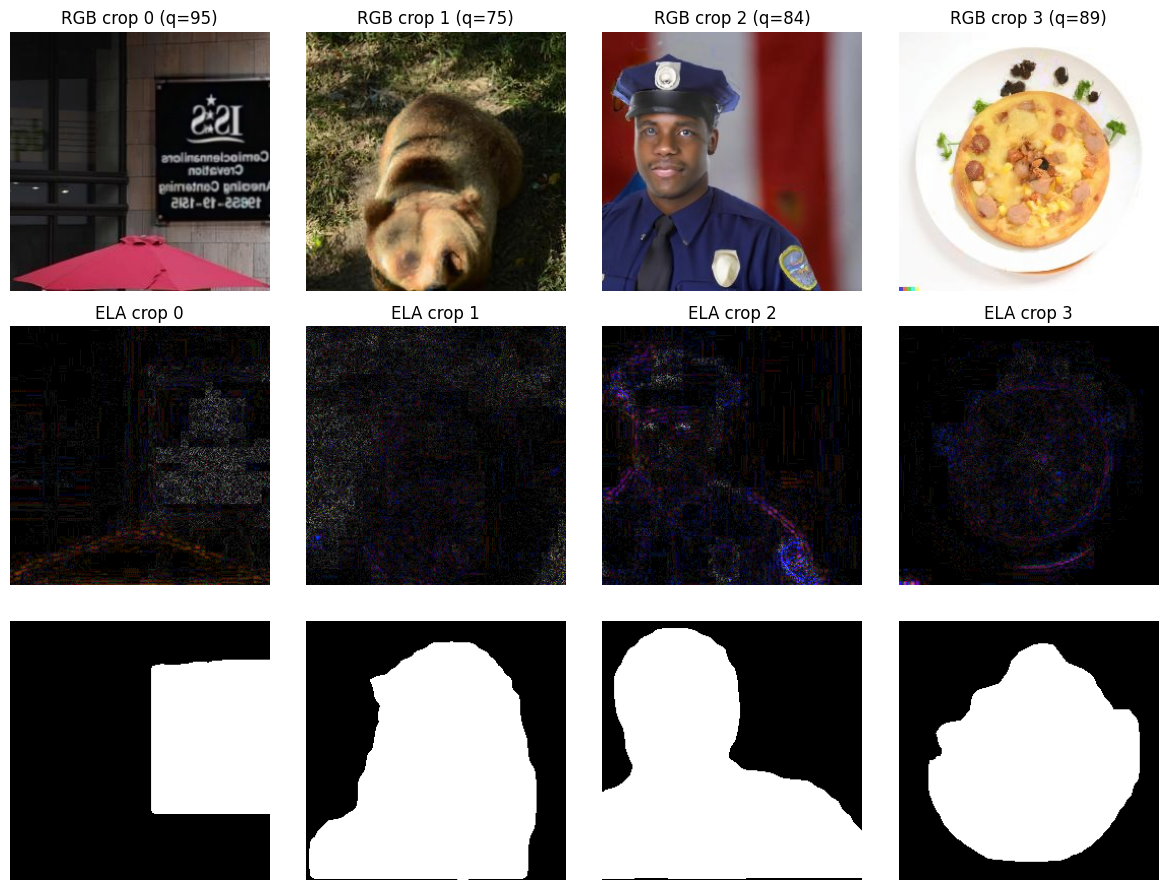

In [4]:
imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_pair(record):
    rgb = load_rgb(record["input_path"])
    if record["kind"] == "normal":
        mask = np.zeros(rgb.shape[:2], dtype=np.uint8)
    else:
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if rgb.shape[:2] != mask.shape:
        raise ValueError(f"이미지와 마스크 크기가 같아야 함: {record['input_path']}")
    return rgb, mask


def ela_of(rgb):
    return make_ela(rgb, quality=config["ela_quality"], scale=config["ela_scale"], subsampling=config["ela_subsampling"])


def jpeg_recompress(rgb, quality):
    with BytesIO() as buffer:
        Image.fromarray(rgb).save(buffer, format="JPEG", quality=int(quality), subsampling=config["aug_subsampling"],
                                  optimize=False, progressive=False)
        buffer.seek(0)
        with Image.open(buffer) as image:
            return np.array(image.convert("RGB"), dtype=np.uint8)


def to_input(rgb, ela):
    parts = [(part.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std for part in (rgb, ela)]
    return torch.from_numpy(np.concatenate(parts, axis=2).transpose(2, 0, 1).copy())


class AugmentedTrainCrops(torch.utils.data.Dataset):
    def __init__(self, records, epoch):
        self.records, self.epoch = records, epoch

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rng = np.random.default_rng([seed, self.epoch, index])
        quality = int(rng.integers(config["aug_quality_min"], config["aug_quality_max"] + 1))
        rgb, mask = load_pair(self.records[index])
        rgb = jpeg_recompress(rgb, quality)
        ela = ela_of(rgb)
        size, stride = config["crop_size"], config["crop_stride"]
        top = int(rng.integers(0, (rgb.shape[0] - size) // stride + 1)) * stride
        left = int(rng.integers(0, (rgb.shape[1] - size) // stride + 1)) * stride
        rgb, mask = crop_pair(rgb, mask, top=top, left=left, height=size, width=size)
        ela = ela[top:top + size, left:left + size].copy()
        if rng.random() < config["flip_probability"]:
            rgb, ela, mask = rgb[:, ::-1].copy(), ela[:, ::-1].copy(), mask[:, ::-1].copy()
        return to_input(rgb, ela), torch.from_numpy(mask[None].astype(np.float32)), quality


def make_train_loader(epoch):
    generator = torch.Generator().manual_seed(seed * 1000 + epoch)
    return torch.utils.data.DataLoader(AugmentedTrainCrops(train_records, epoch), batch_size=config["batch_size"],
                                       shuffle=True, drop_last=True, num_workers=config["num_workers"],
                                       generator=generator, pin_memory=True)


dataset_check = AugmentedTrainCrops(train_records, epoch=1)
a, b = dataset_check[0], dataset_check[0]
assert torch.equal(a[0], b[0]) and torch.equal(a[1], b[1]) and a[2] == b[2], "같은 epoch·샘플은 같은 증강이어야 함."
qualities_check = [AugmentedTrainCrops(train_records, epoch=e)[0][2] for e in range(1, 6)]
assert all(config["aug_quality_min"] <= q <= config["aug_quality_max"] for q in qualities_check)
print("샘플 0의 epoch 1~5 품질:", qualities_check)

x, y, q = next(iter(make_train_loader(1)))
print("배치 입력", tuple(x.shape), x.dtype, "/ 마스크", tuple(y.shape), y.dtype, torch.unique(y).tolist())
print("배치 품질:", q.tolist())
print("epoch당 step:", len(train_records) // config["batch_size"])

figure, axes = plt.subplots(3, 4, figsize=(12, 9))
for column in range(4):
    axes[0, column].imshow((x[column, :3].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[1, column].imshow((x[column, 3:].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[2, column].imshow(y[column, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"RGB crop {column} (q={int(q[column])})")
    axes[1, column].set_title(f"ELA crop {column}")
    for row in range(3):
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. 증강 확인

학습 조작 이미지 한 장을 증강 없이, 그리고 q=70·85·100으로 다시 저장했을 때의 ELA와 마스크 안·밖 ELA 평균을 비교함. 재저장으로 마스크 안·밖의 ELA 차이가 줄어드는지 눈으로 확인하는 용도이며, 여러 장의 정량 측정은 006 EDA에서 함.

확인 이미지: 41491_1.jpg / 마스크 비율 0.443


,setting,ela_inside,ela_outside,ratio_in_out
0,no aug (JPEG100 file),32.648,6.901,4.731
1,q=100,30.357,7.241,4.193
2,q=85,17.557,4.768,3.682
3,q=70,11.562,4.381,2.639


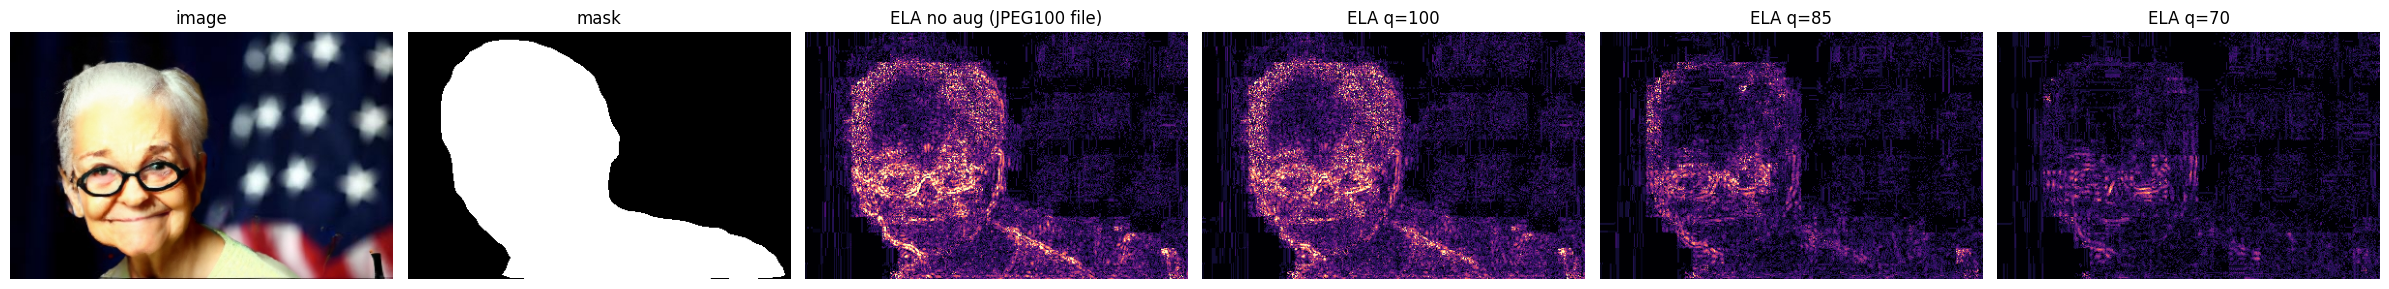

In [5]:
check_record = train_records[int(np.random.default_rng(seed).integers(len(train_records)))]
check_rgb, check_mask = load_pair(check_record)
inside = check_mask > 0
panels, ela_rows = [], []
for label, quality in [("no aug (JPEG100 file)", None), ("q=100", 100), ("q=85", 85), ("q=70", 70)]:
    rgb_q = check_rgb if quality is None else jpeg_recompress(check_rgb, quality)
    ela_q = ela_of(rgb_q).astype(np.float32).mean(axis=2)
    panels.append((ela_q, label))
    ela_rows.append(dict(setting=label, ela_inside=ela_q[inside].mean(), ela_outside=ela_q[~inside].mean(),
                         ratio_in_out=ela_q[inside].mean() / max(ela_q[~inside].mean(), 1e-6)))
print("확인 이미지:", Path(check_record["image_path"]).name, "/ 마스크 비율", round(inside.mean(), 4))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pd.DataFrame(ela_rows))

figure, axes = plt.subplots(1, 6, figsize=(24, 4))
axes[0].imshow(check_rgb)
axes[0].set_title("image")
axes[1].imshow(check_mask, cmap="gray")
axes[1].set_title("mask")
vmax = max(np.percentile(p, 99) for p, _ in panels)
for axis, (ela_q, label) in zip(axes[2:], panels):
    axis.imshow(ela_q, cmap="magma", vmin=0, vmax=vmax)
    axis.set_title(f"ELA {label}")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. 모델·손실·평가 함수

모델·손실·평가 함수는 004와 같은 코드임(ResNet-50 U-Net, 6채널 conv1은 RGB 사전학습 가중치를 ELA 쪽에 복사, 이미지별 Dice, 원본 크기 전체 ELA 후 우하단 패딩 추론, 임계값 0.5, 이미지별 평균).

체크포인트는 런타임(`/content/checkpoints/`)에 먼저 저장하고, 임시 이름으로 Drive에 복사한 뒤 SHA-256이 같으면 최종 이름으로 바꿈(팀 보관 규칙).

In [6]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.block(x)


class ResNet50UNet(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        if in_channels == 6:
            rgb_weight = encoder.conv1.weight.detach().clone()
            encoder.conv1 = nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                encoder.conv1.weight.copy_(torch.cat([rgb_weight, rgb_weight], dim=1))
        elif in_channels != 3:
            raise ValueError("입력 채널은 3 또는 6이어야 함.")
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.layers = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoders = nn.ModuleList([
            DecoderBlock(2048, 1024, 256), DecoderBlock(256, 512, 128), DecoderBlock(128, 256, 64),
            DecoderBlock(64, 64, 32), DecoderBlock(32, 0, 16),
        ])
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        if x.shape[-2] % 32 or x.shape[-1] % 32:
            raise ValueError("입력 높이·너비는 32의 배수여야 함.")
        stem = self.stem(x)
        features = []
        out = self.pool(stem)
        for layer in self.layers:
            out = layer(out)
            features.append(out)
        out = features[-1]
        for decoder, skip in zip(self.decoders, [features[2], features[1], features[0], stem, None]):
            out = decoder(out, skip)
        return self.head(out)


def dice_per_image(logits, target, eps):
    probability = torch.sigmoid(logits)
    intersection = (probability * target).sum(dim=(1, 2, 3))
    total = probability.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + eps) / (total + eps)).mean()


def compute_loss(condition, logits, target):
    if condition == "bce":
        return F.binary_cross_entropy_with_logits(logits, target)
    if condition == "dice":
        return dice_per_image(logits, target, config["dice_eps"])
    if condition == "bce_dice":
        return F.binary_cross_entropy_with_logits(logits, target) + dice_per_image(logits, target, config["dice_eps"])
    raise ValueError(f"알 수 없는 손실 조건: {condition}")


def predict_full(model, rgb):
    padded_rgb, original_size = pad_image(rgb, multiple=config["pad_multiple"])
    padded_ela, _ = pad_image(ela_of(rgb), multiple=config["pad_multiple"])
    with torch.no_grad():
        logits = model(to_input(padded_rgb, padded_ela)[None].to(device, non_blocking=True))
    probability = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
    return unpad_image(probability, original_size=original_size)


def evaluate(model, records, keep=None):
    model.eval()
    rows, kept = [], {}
    for record in records:
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, tn = confusion_counts(mask, prediction)
        row = {k: record.get(k) for k in ("dataset", "split", "variant", "input_conversion", "kind", "original_id")}
        row.update(image=Path(record["image_path"]).name, height=mask.shape[0], width=mask.shape[1],
                   tp=tp, fp=fp, fn=fn, tn=tn, f1=None, iou=None, fpr=None)
        if record["kind"] == "manipulated":
            row.update(f1=pixel_f1(tp, fp, fn), iou=iou(tp, fp, fn))
        else:
            row.update(fpr=false_positive_rate(fp, tn))
        rows.append(row)
        if keep is not None and str(record["input_path"]) in keep:
            kept[str(record["input_path"])] = (rgb, ela_of(rgb), mask, probability)
    frame = pd.DataFrame(rows)
    for column in ("f1", "iou", "fpr"):
        frame[column] = pd.to_numeric(frame[column])
    return (frame, kept) if keep is not None else frame




def verified_copy(source, target):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_name(target.name + ".tmp")
    shutil.copyfile(source, temporary)
    source_hash, copied_hash = sha256(source), sha256(temporary)
    if source_hash != copied_hash:
        temporary.unlink()
        raise IOError(f"복사본 SHA-256이 원본과 달라 교체하지 않음: {target}")
    os.replace(temporary, target)
    return source_hash


def save_checkpoint(payload, name):
    local_ckpt_root.mkdir(parents=True, exist_ok=True)
    local_path = local_ckpt_root / name
    torch.save(payload, local_path)
    verified_copy(local_path, run_root / name)
    return local_path


def copy_to_shared(local_path):
    try:
        file_hash = verified_copy(local_path, shared_ckpt_path)
        return True, file_hash
    except Exception as error:
        print(f"[경고] 공유 Drive 보관 실패, 이전 검증본 유지. 9번 셀에서 다시 시도함: {error}")
        return False, None


def summarize(rows):
    return rows.groupby(["dataset", "kind", "variant"], sort=False).agg(
        images=("image", "size"), pixel_f1=("f1", "mean"), iou=("iou", "mean"), normal_pixel_fpr=("fpr", "mean")).reset_index()


model = ResNet50UNet(6).to(device)
reference_conv1 = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2).conv1.weight.detach().to(device)
assert torch.equal(model.stem[0].weight[:, :3], reference_conv1) and torch.equal(model.stem[0].weight[:, 3:], reference_conv1)
with torch.no_grad():
    for shape in [(2, 6, 256, 256), (1, 6, 256, 384)]:
        assert model(torch.randn(shape, device=device)).shape == (shape[0], 1, shape[2], shape[3])
print("파라미터 수:", sum(p.numel() for p in model.parameters()))
del model, reference_conv1

shared_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
probe_path = shared_ckpt_path.parent / f".{experiment_name}_write_check"
probe_path.write_text("ok")
probe_path.unlink()
print("공유 체크포인트 폴더 쓰기 가능:", shared_ckpt_path.parent)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


파라미터 수: 32530385
공유 체크포인트 폴더 쓰기 가능: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet


## 6. 학습

시드 42로 모델을 초기화하고 Adam 1e-4로 학습함. 매 epoch 끝에 val 조작 361장을 JPEG 100·90·75에서 각각, val 정상 227장을 한 번 원본 크기로 평가함.

- 세 품질 평균 F1이 최고이면 `best_mean.pt`를 저장하고 공유 Drive에 보관함. 5 epoch 연속 평균 F1 개선이 없으면 종료함.
- JPEG100 F1이 최고이면 `best_q100.pt`를 개인 폴더에 저장함.
- 매 epoch 끝에 `last.pt`(모델·옵티마이저·기록)와 `history.csv`를 저장함. **세션이 끊기면 이 셀만 다시 실행하면 마지막으로 끝난 epoch 다음부터 이어서 학습함.** 학습이 끝나면 `done.json`을 남기고, 다시 실행하면 학습을 건너뜀. 설정 해시가 다른 기록이 있으면 덮어쓰지 않고 중단함.

In [7]:
run_root.mkdir(parents=True, exist_ok=True)
last_path, done_path = run_root / "last.pt", run_root / "done.json"


def evaluate_val(model):
    row, timing = {}, time.perf_counter()
    f1s = []
    for quality in config["val_qualities"]:
        frame = evaluate(model, val_manipulated[quality])
        row[f"val_f1_q{quality}"], row[f"val_iou_q{quality}"] = frame.f1.mean(), frame.iou.mean()
        f1s.append(frame.f1.mean())
    row["val_f1_mean"] = float(np.mean(f1s))
    row["val_normal_fpr"] = evaluate(model, val_normal).fpr.mean()
    row["val_seconds"] = time.perf_counter() - timing
    return row


if done_path.is_file():
    done = json.loads(done_path.read_text())
    if done["config_hash"] != config_hash:
        raise ValueError(f"다른 설정의 완료 기록이 있음. 폴더를 확인해야 함: {run_root}")
    history = pd.read_csv(run_root / "history.csv")
    print(f"완료 기록 사용: best_mean epoch {done['best_mean_epoch']} (val 평균 F1 {done['best_mean_f1']:.4f}), "
          f"best_q100 epoch {done['best_q100_epoch']} (val JPEG100 F1 {done['best_q100_f1']:.4f})")
else:
    set_seed(seed)
    model = ResNet50UNet(6).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    state = dict(epoch=0, rows=[], best_mean=(-1.0, 0), best_q100=(-1.0, 0), stale=0)
    if last_path.is_file():
        last = torch.load(last_path, map_location=device, weights_only=False)
        if last["config_hash"] != config_hash:
            raise ValueError(f"다른 설정의 재시작 파일이 있음. 폴더를 확인해야 함: {last_path}")
        model.load_state_dict(last["state_dict"])
        optimizer.load_state_dict(last["optimizer"])
        state = last["state"]
        # last.pt를 저장한 직후 최선 파일 저장 전에 끊긴 경우, last.pt의 모델로 최선 파일을 다시 만듦
        for name, key in [("best_mean.pt", "best_mean"), ("best_q100.pt", "best_q100")]:
            best_epoch = state[key][1]
            saved_epoch = torch.load(run_root / name, map_location="cpu", weights_only=False)["epoch"] if (run_root / name).is_file() else None
            if best_epoch and saved_epoch != best_epoch:
                if best_epoch != state["epoch"]:
                    raise RuntimeError(f"{name}의 epoch({saved_epoch})가 기록({best_epoch})과 달라 복구할 수 없음.")
                save_checkpoint({"epoch": best_epoch, "selection": key, "config": config, "config_hash": config_hash,
                                 "state_dict": last["state_dict"]}, name)
                print(f"{name}을 last.pt에서 복구함 (epoch {best_epoch})")
        del last
        print(f"재시작: epoch {state['epoch']}까지 완료된 기록에서 이어서 학습함")
    torch.cuda.reset_peak_memory_stats()
    shared_ok = True
    if state["best_mean"][1]:
        shared_ok, _ = copy_to_shared(run_root / "best_mean.pt")

    for epoch in range(state["epoch"] + 1, config["max_epochs"] + 1):
        if state["stale"] >= config["patience"]:
            break
        model.train()
        start = time.perf_counter()
        losses, qualities = [], []
        for x, y, q in make_train_loader(epoch):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = compute_loss(config["loss"], model(x), y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"epoch {epoch}: 손실이 유한해야 함.")
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            qualities.extend(q.tolist())
        train_seconds = time.perf_counter() - start

        row = dict(epoch=epoch, train_loss=float(np.mean(losses)), aug_q_mean=float(np.mean(qualities)),
                   aug_q_min=int(min(qualities)), aug_q_max=int(max(qualities)), train_seconds=train_seconds)
        row.update(evaluate_val(model))
        improved_mean = row["val_f1_mean"] > state["best_mean"][0]
        improved_q100 = row["val_f1_q100"] > state["best_q100"][0]
        if improved_mean:
            state["best_mean"], state["stale"] = (row["val_f1_mean"], epoch), 0
        else:
            state["stale"] += 1
        if improved_q100:
            state["best_q100"] = (row["val_f1_q100"], epoch)
        row.update(best_mean=improved_mean, best_q100=improved_q100)
        state["rows"].append(row)
        state["epoch"] = epoch

        payload = {"epoch": epoch, "config": config, "config_hash": config_hash, "state_dict": model.state_dict()}
        save_checkpoint(dict(payload, optimizer=optimizer.state_dict(), state=state), "last.pt")
        if improved_mean:
            local_best = save_checkpoint(dict(payload, selection="best_mean"), "best_mean.pt")
            shared_ok, _ = copy_to_shared(local_best)
        if improved_q100:
            save_checkpoint(dict(payload, selection="best_q100"), "best_q100.pt")
        pd.DataFrame(state["rows"]).to_csv(run_root / "history.csv", index=False)

        print(f"epoch {epoch:2d} loss {row['train_loss']:.4f} q̄ {row['aug_q_mean']:.1f} | val F1 "
              f"100 {row['val_f1_q100']:.4f} 90 {row['val_f1_q90']:.4f} 75 {row['val_f1_q75']:.4f} "
              f"mean {row['val_f1_mean']:.4f} | normal FPR {row['val_normal_fpr']:.4f} | "
              f"train {train_seconds:.0f}s val {row['val_seconds']:.0f}s"
              f"{' *mean' if improved_mean else ''}{' *q100' if improved_q100 else ''}")
    if state["stale"] >= config["patience"]:
        print(f"{config['patience']} epoch 동안 평균 F1 개선 없음. 조기 종료")

    history = pd.DataFrame(state["rows"])
    done = dict(config_hash=config_hash, epochs_run=state["epoch"],
                best_mean_epoch=state["best_mean"][1], best_mean_f1=state["best_mean"][0],
                best_q100_epoch=state["best_q100"][1], best_q100_f1=state["best_q100"][0],
                peak_gpu_gib_last_session=torch.cuda.max_memory_allocated() / 1024**3,
                shared_copy_ok=shared_ok, finished_utc=datetime.now(timezone.utc).isoformat())
    done_path.write_text(json.dumps(done, indent=1))
    print(f"종료: best_mean epoch {done['best_mean_epoch']} (평균 F1 {done['best_mean_f1']:.4f}), "
          f"best_q100 epoch {done['best_q100_epoch']} (JPEG100 F1 {done['best_q100_f1']:.4f})")
    del model, optimizer
    torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


epoch  1 loss 1.0124 q̄ 85.2 | val F1 100 0.8152 90 0.6516 75 0.6215 mean 0.6961 | normal FPR 0.1249 | train 72s val 56s *mean *q100
epoch  2 loss 0.8576 q̄ 84.9 | val F1 100 0.8544 90 0.7053 75 0.7146 mean 0.7581 | normal FPR 0.2230 | train 81s val 56s *mean *q100
epoch  3 loss 0.7791 q̄ 84.6 | val F1 100 0.8519 90 0.7441 75 0.7488 mean 0.7816 | normal FPR 0.3234 | train 89s val 57s *mean
epoch  4 loss 0.7091 q̄ 85.3 | val F1 100 0.8965 90 0.7130 75 0.7316 mean 0.7804 | normal FPR 0.1986 | train 80s val 64s *q100
epoch  5 loss 0.6525 q̄ 84.9 | val F1 100 0.8812 90 0.6924 75 0.7249 mean 0.7662 | normal FPR 0.1923 | train 84s val 58s
epoch  6 loss 0.6034 q̄ 85.2 | val F1 100 0.9030 90 0.6945 75 0.7282 mean 0.7752 | normal FPR 0.1580 | train 80s val 61s *q100
epoch  7 loss 0.5566 q̄ 85.1 | val F1 100 0.8876 90 0.7560 75 0.7691 mean 0.8042 | normal FPR 0.2827 | train 82s val 61s *mean
epoch  8 loss 0.5172 q̄ 84.8 | val F1 100 0.9005 90 0.7595 75 0.7597 mean 0.8066 | normal FPR 0.2046 | tr

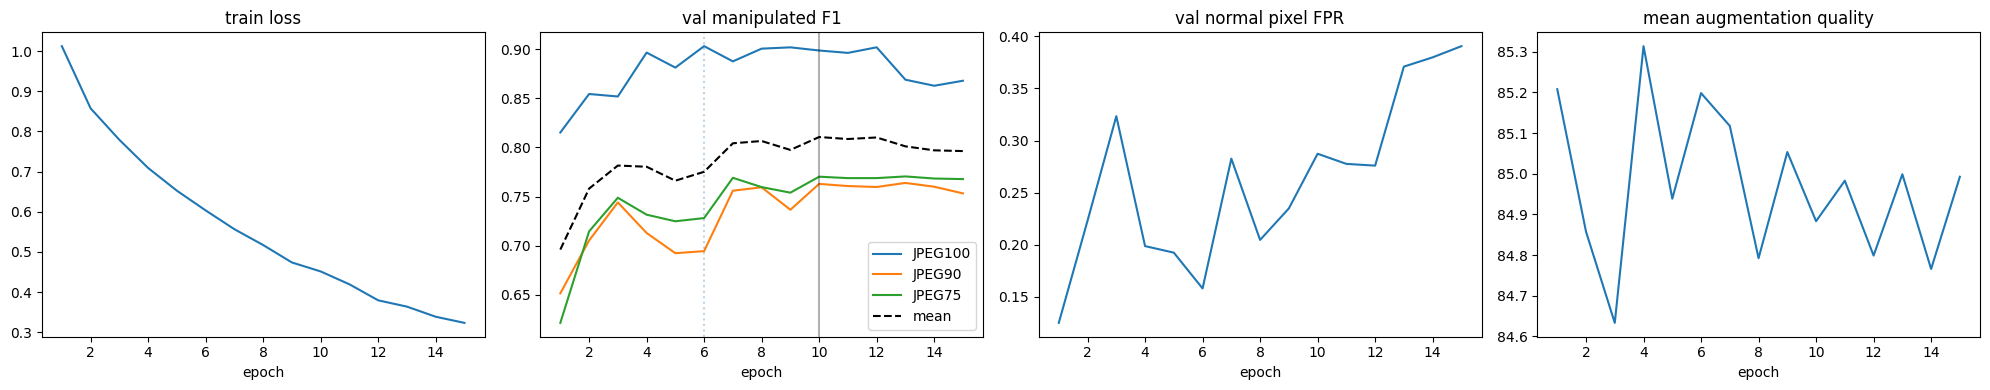

,selection,epoch,val_f1_q100,val_f1_q90,val_f1_q75,val_f1_mean,val_normal_fpr
0,best_mean,10,0.898638,0.762940,0.770259,0.810612,0.287324
1,best_q100,6,0.903049,0.694507,0.728177,0.775244,0.157972


학습 epoch 수: 15 / 전체 학습·검증 시간(분): 37.1
두 기준의 선택 epoch가 다름


In [8]:
history = pd.read_csv(run_root / "history.csv")
done = json.loads((run_root / "done.json").read_text())
figure, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history.epoch, history.train_loss)
axes[0].set_title("train loss")
for quality in config["val_qualities"]:
    axes[1].plot(history.epoch, history[f"val_f1_q{quality}"], label=f"JPEG{quality}")
axes[1].plot(history.epoch, history.val_f1_mean, "k--", label="mean")
axes[1].axvline(done["best_mean_epoch"], color="k", alpha=0.3)
axes[1].axvline(done["best_q100_epoch"], color="tab:blue", alpha=0.3, linestyle=":")
axes[1].set_title("val manipulated F1")
axes[1].legend()
axes[2].plot(history.epoch, history.val_normal_fpr)
axes[2].set_title("val normal pixel FPR")
axes[3].plot(history.epoch, history.aug_q_mean)
axes[3].set_title("mean augmentation quality")
for axis in axes:
    axis.set_xlabel("epoch")
plt.tight_layout()
plt.show()

columns = ["epoch", "val_f1_q100", "val_f1_q90", "val_f1_q75", "val_f1_mean", "val_normal_fpr"]
selected = history.set_index("epoch").loc[[done["best_mean_epoch"], done["best_q100_epoch"]]].reset_index()[columns]
selected.insert(0, "selection", ["best_mean", "best_q100"])
with pd.option_context("display.float_format", "{:.6f}".format):
    display(selected)
print("학습 epoch 수:", done["epochs_run"], "/ 전체 학습·검증 시간(분):",
      round((history.train_seconds.sum() + history.val_seconds.sum()) / 60, 1))
print("두 기준의 선택 epoch가 같음" if done["best_mean_epoch"] == done["best_q100_epoch"] else "두 기준의 선택 epoch가 다름")

## 7. 테스트 평가

테스트 셀은 모델별로 나눠져 있어 따로 실행할 수 있음. 각 셀은 결과를 Drive의 하위 폴더에 `test_rows.csv`와 `done.json`(체크포인트 SHA-256 포함)으로 남기고, 다시 실행하면 같은 체크포인트의 결과를 불러오기만 함. test 결과로 설정을 바꾸지 않음.

### 7-1. 005 대표 결과(`best_mean`)

공유 Drive 보관본을 원본과 대조하고(실패했으면 다시 복사), 경로·선택 epoch·크기·SHA-256을 출력한 뒤 테스트함.

In [9]:
def load_model(path):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model = ResNet50UNet(6).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint


def run_test(tag, checkpoint_path, records):
    out_dir = run_root / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_hash = sha256(checkpoint_path)
    marker = out_dir / "done.json"
    if marker.is_file():
        saved = json.loads(marker.read_text())
        if saved["checkpoint_sha256"] == checkpoint_hash and saved["config_hash"] == config_hash:
            print(f"[{tag}] 저장된 테스트 결과 사용 (epoch {saved['epoch']})")
            return pd.read_csv(out_dir / "test_rows.csv")
    model, checkpoint = load_model(checkpoint_path)
    start = time.perf_counter()
    rows = evaluate(model, records)
    seconds = time.perf_counter() - start
    rows.to_csv(out_dir / "test_rows.csv", index=False)
    marker.write_text(json.dumps(dict(epoch=int(checkpoint["epoch"]), checkpoint=str(checkpoint_path),
                                      checkpoint_sha256=checkpoint_hash, config_hash=config_hash,
                                      images=len(rows), seconds=seconds), indent=1))
    print(f"[{tag}] epoch {checkpoint['epoch']}, test {len(rows)}장 평가 {seconds:.0f}s")
    del model
    torch.cuda.empty_cache()
    return rows


def show_summary(rows, title):
    print(title)
    with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None, "display.width", 200):
        display(summarize(rows))


done = json.loads((run_root / "done.json").read_text())
best_mean_path = run_root / "best_mean.pt"
if not shared_ckpt_path.is_file() or sha256(shared_ckpt_path) != sha256(best_mean_path):
    print("공유 Drive 보관본이 없거나 다름. 다시 복사함")
    verified_copy(best_mean_path, shared_ckpt_path)
shared_epoch = torch.load(shared_ckpt_path, map_location="cpu", weights_only=False)["epoch"]
assert shared_epoch == done["best_mean_epoch"]
print("공유 체크포인트:", shared_ckpt_path)
print("선택 epoch:", shared_epoch, "/ 크기:", f"{shared_ckpt_path.stat().st_size / 1024**2:.1f} MiB", "/ SHA-256:", sha256(shared_ckpt_path))

rows_mean = run_test("test_best_mean", best_mean_path, test_records)
show_summary(rows_mean, f"005 best_mean (epoch {done['best_mean_epoch']})")

공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug_best.pt
선택 epoch: 10 / 크기: 124.4 MiB / SHA-256: 5001fe5d2c8a76ad8b44d65432ef9e5b4a71f72e7927b0c5ab88543d81059a57
[test_best_mean] epoch 10, test 4305장 평가 139s
005 best_mean (epoch 10)


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.322640
1,AutoSplice,manipulated,JPEG100,335,0.913669,0.866156,NaN
2,AutoSplice,manipulated,JPEG90,335,0.787214,0.689238,NaN
3,AutoSplice,manipulated,JPEG75,335,0.793707,0.698656,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.957112
5,CocoGlide,manipulated,JPEG100_444,512,0.364916,0.262162,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.505091
7,CocoGlide,manipulated,JPEG90_444,512,0.357515,0.261167,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.491406
9,CocoGlide,manipulated,JPEG75_444,512,0.400454,0.293651,NaN


### 7-2. 005 기준 통일 확인(`best_q100`)

004와 같은 기준(val JPEG100 F1)으로 고른 epoch를 테스트함. 7-1과 같은 epoch면 7-1 결과를 그대로 씀.

In [10]:
done = json.loads((run_root / "done.json").read_text())
if done["best_q100_epoch"] == done["best_mean_epoch"]:
    rows_q100 = pd.read_csv(run_root / "test_best_mean" / "test_rows.csv")
    print(f"best_q100도 epoch {done['best_q100_epoch']}로 같음. 7-1 결과를 사용함")
else:
    rows_q100 = run_test("test_best_q100", run_root / "best_q100.pt", test_records)
show_summary(rows_q100, f"005 best_q100 (epoch {done['best_q100_epoch']})")

[test_best_q100] epoch 6, test 4305장 평가 138s
005 best_q100 (epoch 6)


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.166150
1,AutoSplice,manipulated,JPEG100,335,0.915915,0.861066,NaN
2,AutoSplice,manipulated,JPEG90,335,0.702618,0.583203,NaN
3,AutoSplice,manipulated,JPEG75,335,0.743322,0.629099,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.899233
5,CocoGlide,manipulated,JPEG100_444,512,0.365395,0.261449,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.242381
7,CocoGlide,manipulated,JPEG90_444,512,0.327583,0.236824,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.236361
9,CocoGlide,manipulated,JPEG75_444,512,0.382058,0.281526,NaN


### 7-3. 004 모델(증강 없음) CocoGlide 100·90·75

004의 최선 체크포인트(개인 폴더)를 불러와 CocoGlide를 세 품질로 평가함. CocoGlide JPEG100은 004 노트북의 저장 결과와 같은지 대조용으로 다시 평가함. AutoSplice 결과는 004 노트북의 `test_rows.csv`를 그대로 씀.

In [11]:
ref_checkpoint_path = ref004_dir / "best.pt"
ref_checkpoint = torch.load(ref_checkpoint_path, map_location="cpu", weights_only=False)
same_keys = ["input_mode", "in_channels", "ela_quality", "ela_scale", "ela_subsampling", "crop_size", "encoder",
             "encoder_weights", "normalization", "conv1", "threshold", "pad_multiple", "seed"]
mismatch = {k: (ref_checkpoint["config"].get(k), config[k]) for k in same_keys if ref_checkpoint["config"].get(k) != config[k]}
if mismatch:
    raise ValueError(f"004 체크포인트 설정이 비교 기준과 같아야 함: {mismatch}")
print("004 체크포인트:", ref_checkpoint_path, "/ epoch", ref_checkpoint["epoch"], "/ SHA-256:", sha256(ref_checkpoint_path))
del ref_checkpoint

coco_records = [r for r in test_records if r["dataset"] == "CocoGlide"]
rows_ref_coco = run_test("ref_004_cocoglide", ref_checkpoint_path, coco_records)
ref_saved = pd.read_csv(ref004_dir / "test_rows.csv")
ref_saved_coco100 = ref_saved[ref_saved.dataset == "CocoGlide"]
new_coco100 = rows_ref_coco[rows_ref_coco.variant == "JPEG100_444"]
for kind, column in [("manipulated", "f1"), ("normal", "fpr")]:
    old = ref_saved_coco100[ref_saved_coco100.kind == kind][column].mean()
    new = new_coco100[new_coco100.kind == kind][column].mean()
    print(f"CocoGlide JPEG100 {kind} {column}: 004 저장값 {old:.6f} / 재평가 {new:.6f} / 차이 {new - old:+.2e}")

rows_ref = pd.concat([ref_saved[ref_saved.dataset == "AutoSplice"], rows_ref_coco], ignore_index=True)
show_summary(rows_ref, "004 (증강 없음): AutoSplice는 004 저장값, CocoGlide는 재평가")

004 체크포인트: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_004_rgb_ela_unet_baseline/bce_dice/best.pt / epoch 25 / SHA-256: 598c72389cfd0e93bd577d70b3b4c3428f6e75c6fe682a3641b1db2bc73c773b
[ref_004_cocoglide] epoch 25, test 3072장 평가 90s
CocoGlide JPEG100 manipulated f1: 004 저장값 0.361080 / 재평가 0.361086 / 차이 +5.82e-06
CocoGlide JPEG100 normal fpr: 004 저장값 0.975726 / 재평가 0.975685 / 차이 -4.08e-05
004 (증강 없음): AutoSplice는 004 저장값, CocoGlide는 재평가


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.000934
1,AutoSplice,manipulated,JPEG100,335,0.971787,0.946339,NaN
2,AutoSplice,manipulated,JPEG90,335,0.004701,0.002771,NaN
3,AutoSplice,manipulated,JPEG75,335,0.007563,0.004829,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.975685
5,CocoGlide,manipulated,JPEG100_444,512,0.361086,0.258608,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.265555
7,CocoGlide,manipulated,JPEG90_444,512,0.170326,0.112671,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.280365
9,CocoGlide,manipulated,JPEG75_444,512,0.236084,0.158642,NaN


## 8. 004 vs 005 비교

품질별 점수와 JPEG100 대비 하락 폭을 나란히 비교함. 조작 이미지는 이미지별 F1 평균, 정상 이미지는 이미지별 픽셀 오탐률 평균임. 예측 그림은 test에서 고정 시드로 고른 AutoSplice·CocoGlide 조작 이미지 한 장씩을 JPEG100과 JPEG75로 보여 줌.

model                                          004 no aug  005 best_mean  \
dataset    kind        metric     variant                                  
AutoSplice normal      normal FPR original       0.000934       0.322640   
           manipulated F1         JPEG100        0.971787       0.913669   
                                  JPEG90         0.004701       0.787214   
                                  JPEG75         0.007563       0.793707   
CocoGlide  normal      normal FPR JPEG100_444    0.975685       0.957112   
                                  JPEG90_444     0.265555       0.505091   
                                  JPEG75_444     0.280365       0.491406   
           manipulated F1         JPEG100_444    0.361086       0.364916   
                                  JPEG90_444     0.170326       0.357515   
                                  JPEG75_444     0.236084       0.400454   

model                                          005 best_q100  
dataset    kind        metric     variant                     
AutoSplice normal      normal FPR original          0.166150  
           manipulated F1         JPEG100           0.915915  
                                  JPEG90            0.702618  
                                  JPEG75            0.743322  
CocoGlide  normal      normal FPR JPEG100_444       0.899233  
                                  JPEG90_444        0.242381  
                                  JPEG75_444        0.236361  
           manipulated F1         JPEG100_444       0.365395  
                                  JPEG90_444        0.327583  
                                  JPEG75_444        0.382058

,dataset,model,f1_jpeg100,drop_to_90,drop_to_75
0,AutoSplice,004 no aug,+0.971787,-0.967087,-0.964224
1,AutoSplice,005 best_mean,+0.913669,-0.126455,-0.119962
2,AutoSplice,005 best_q100,+0.915915,-0.213297,-0.172592
3,CocoGlide,004 no aug,+0.361086,-0.190760,-0.125002
4,CocoGlide,005 best_mean,+0.364916,-0.007402,+0.035538
5,CocoGlide,005 best_q100,+0.365395,-0.037812,+0.016663


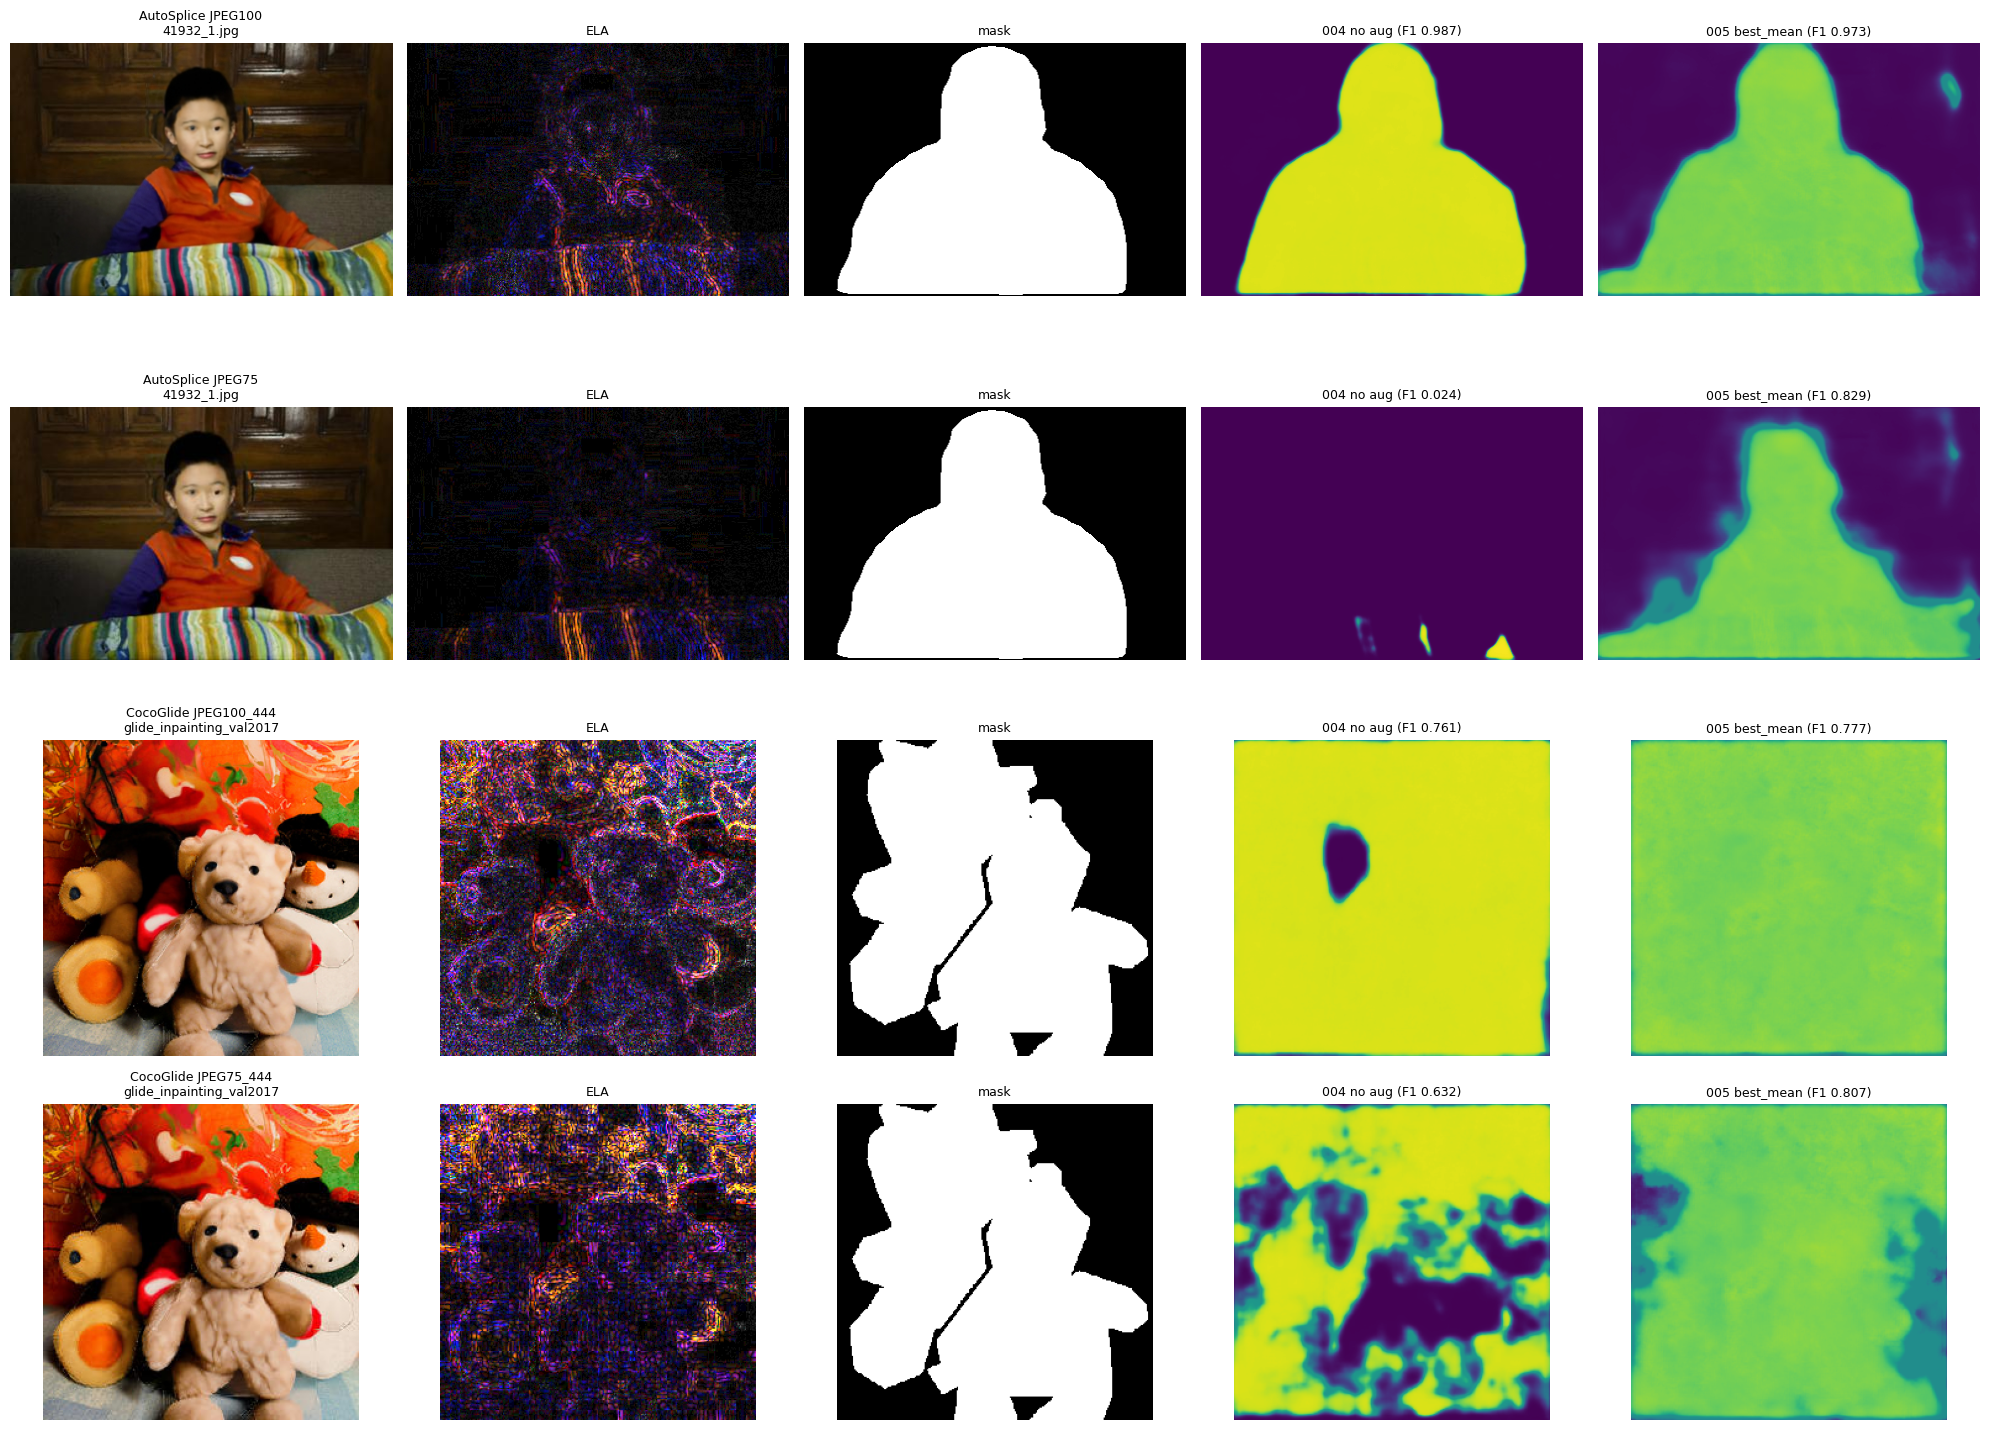

In [12]:
models = {"004 no aug": rows_ref, "005 best_mean": rows_mean, "005 best_q100": rows_q100}
tables = []
for name, rows in models.items():
    summary = summarize(rows)
    summary["metric"] = np.where(summary.kind == "manipulated", "F1", "normal FPR")
    summary["score"] = summary.pixel_f1.fillna(summary.normal_pixel_fpr)
    summary["model"] = name
    tables.append(summary)
long = pd.concat(tables, ignore_index=True)
comparison = long.pivot_table(index=["dataset", "kind", "metric", "variant"], columns="model", values="score", sort=False)[list(models)]
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None):
    display(comparison)

drops = []
for dataset, prefix, suffix in [("AutoSplice", "JPEG", ""), ("CocoGlide", "JPEG", "_444")]:
    for name in models:
        f1 = comparison.loc[(dataset, "manipulated", "F1")][name]
        base_score = f1[f"{prefix}100{suffix}"]
        drops.append(dict(dataset=dataset, model=name, f1_jpeg100=base_score,
                          drop_to_90=f1[f"{prefix}90{suffix}"] - base_score, drop_to_75=f1[f"{prefix}75{suffix}"] - base_score))
with pd.option_context("display.float_format", "{:+.6f}".format):
    display(pd.DataFrame(drops))

vis_rng = np.random.default_rng(seed)
lookup = {(r["dataset"], r["kind"], r["variant"], Path(r["image_path"]).name): r for r in test_records}
picks = []
for dataset, v100, v75 in [("AutoSplice", "JPEG100", "JPEG75"), ("CocoGlide", "JPEG100_444", "JPEG75_444")]:
    names = sorted(k[3] for k in lookup if k[0] == dataset and k[1] == "manipulated" and k[2] == v100)
    name = names[int(vis_rng.integers(len(names)))]
    picks += [lookup[(dataset, "manipulated", v100, name)], lookup[(dataset, "manipulated", v75, name)]]

vis_models = {"004 no aug": load_model(ref_checkpoint_path)[0], "005 best_mean": load_model(run_root / "best_mean.pt")[0]}
figure, axes = plt.subplots(len(picks), 3 + len(vis_models), figsize=(4 * (3 + len(vis_models)), 3.6 * len(picks)))
for row, record in enumerate(picks):
    rgb, mask = load_pair(record)
    panels = [(rgb, f"{record['dataset']} {record['variant']}\n{Path(record['image_path']).name[:24]}", None),
              (ela_of(rgb), "ELA", None), (mask, "mask", "gray")]
    for name, model in vis_models.items():
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, _ = confusion_counts(mask, prediction)
        panels.append((probability, f"{name} (F1 {pixel_f1(tp, fp, fn):.3f})", "viridis"))
    for column, (image, title, cmap) in enumerate(panels):
        axes[row, column].imshow(image, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axes[row, column].set_title(title, fontsize=9)
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()
del vis_models

## 9. 확인 결과와 검토 메모

아래 셀은 실행 범위를 요약함. 해석과 성공·실패 사례 분석은 보고서에 작성함.

사람 검토 메모(실행 후 작성):

- 3·4절 증강 크롭과 ELA 그림(품질에 따른 ELA 변화, 마스크 대응):
- 6절 학습 곡선(품질별 val F1, 두 선택 기준의 epoch 차이, 조기 종료 시점):
- 8절 비교표와 예측 그림(하락 폭 변화, CocoGlide 오탐):
- 특이사항(실행 시간, 끊김·재시작 여부, 공유 Drive 보관 결과 등):

In [13]:
done = json.loads((run_root / "done.json").read_text())
print("설정 해시:", config_hash)
print("실행 기록 폴더:", run_root)
print(f"학습 {done['epochs_run']} epoch, best_mean epoch {done['best_mean_epoch']} (val 평균 F1 {done['best_mean_f1']:.6f}), "
      f"best_q100 epoch {done['best_q100_epoch']} (val JPEG100 F1 {done['best_q100_f1']:.6f})")
print("공유 체크포인트:", shared_ckpt_path, "/ SHA-256:", sha256(shared_ckpt_path))
print("테스트 행 수: 005 best_mean", len(rows_mean), "/ 005 best_q100", len(rows_q100), "/ 004", len(rows_ref))
print("실험 완료. test 결과로 설정을 바꾸지 않음")

설정 해시: ef6315f99363
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug
학습 15 epoch, best_mean epoch 10 (val 평균 F1 0.810612), best_q100 epoch 6 (val JPEG100 F1 0.903049)
공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug_best.pt / SHA-256: 5001fe5d2c8a76ad8b44d65432ef9e5b4a71f72e7927b0c5ab88543d81059a57
테스트 행 수: 005 best_mean 4305 / 005 best_q100 4305 / 004 4305
실험 완료. test 결과로 설정을 바꾸지 않음


## 10. 추가 분석: 예측에 위치 정보가 있는가

8절의 F1·오탐률만으로는 "정답 위치를 찾은 것"과 "칠하는 양만 바뀐 것"을 구분할 수 없음. 004·005 두 체크포인트로 조작 이미지와 같은 장면의 정상 이미지를 다시 추론해 아래 지표를 계산함. test 결과로 설정을 바꾸지 않으며, 7·8절의 결과는 바꾸지 않음.

- **픽셀 AUC:** 조작 이미지마다 예측 확률이 마스크 안 픽셀에서 밖보다 높은 정도(임계값 없음). 0.5면 위치 정보 없음. 확률을 1,000구간으로 나눠 계산함.
- **마스크 섞기 F1:** 같은 데이터셋·변형의 다른 이미지 마스크(정렬 순서상 다음 이미지, 크기가 다르면 최근접 보간)로 잰 F1. 자기 마스크 F1과 비슷하면 위치와 무관한 예측임.
- **쌍 차이 AUC:** 조작 이미지 확률에서 같은 장면 정상 이미지의 확률을 뺀 차이 지도로 잰 픽셀 AUC. 장면 내용 때문에 칠한 부분은 상쇄됨. AutoSplice의 정상 짝은 Q75 원본, CocoGlide는 같은 품질로 변환한 정상본임. 크기가 다르면 계산하지 않음.
- **전부 조작 기준선:** 모든 픽셀을 조작으로 예측했을 때의 F1.

결과는 모델별로 Drive의 `diagnostics/`에 저장하고, 같은 체크포인트면 다시 실행할 때 불러오기만 함.

[004 no aug] 500/2541 38s
[004 no aug] 1000/2541 75s
[004 no aug] 1500/2541 106s
[004 no aug] 2000/2541 135s
[004 no aug] 2500/2541 163s
[004 no aug] epoch 25, 조작 2541장 진단 171s
[005 best_mean] 500/2541 35s
[005 best_mean] 1000/2541 73s
[005 best_mean] 1500/2541 104s
[005 best_mean] 2000/2541 132s
[005 best_mean] 2500/2541 161s
[005 best_mean] epoch 10, 조작 2541장 진단 163s
[005 best_q100] 500/2541 38s
[005 best_q100] 1000/2541 74s
[005 best_q100] 1500/2541 102s
[005 best_q100] 2000/2541 131s
[005 best_q100] 2500/2541 161s
[005 best_q100] epoch 6, 조작 2541장 진단 163s


images     f1  f1_shuffled_mask  f1_all_ones  pixel_auc  pair_diff_auc  pairs  prob_inside  prob_outside  pair_prob_mean  f1_gain_over_shuffled
dataset    variant     model                                                                                                                                                         
AutoSplice JPEG100     004 no aug        335 0.9718            0.7195       0.5404     0.9976         0.9930    335       0.9261        0.0283          0.0021                 0.2523
           JPEG90      004 no aug        335 0.0047            0.0043       0.5404     0.3252         0.4538    335       0.0035        0.0009          0.0021                 0.0004
           JPEG75      004 no aug        335 0.0076            0.0047       0.5404     0.3305         0.4941    335       0.0053        0.0010          0.0021                 0.0028
CocoGlide  JPEG100_444 004 no aug        512 0.3611            0.3560       0.3546     0.5624         0.4919    512       0.9364        0.8975          0.9154                 0.0051
           JPEG90_444  004 no aug        512 0.1703            0.1687       0.3546     0.4654         0.4385    512       0.2427        0.2396          0.2533                 0.0017
           JPEG75_444  004 no aug        512 0.2361            0.1908       0.3546     0.5518         0.4630    512       0.3429        0.2540          0.2681                 0.0453
AutoSplice JPEG100     005 best_mean     335 0.9137            0.7007       0.5404     0.9877         0.9025    335       0.7942        0.0976          0.3272                 0.2130
           JPEG90      005 best_mean     335 0.7872            0.6313       0.5404     0.9334         0.7422    335       0.7030        0.1540          0.3272                 0.1559
           JPEG75      005 best_mean     335 0.7937            0.6288       0.5404     0.9339         0.7653    335       0.7034        0.1468          0.3272                 0.1649
CocoGlide  JPEG100_444 005 best_mean     512 0.3649            0.3550       0.3546     0.5278         0.4675    512       0.7969        0.7608          0.7747                 0.0100
           JPEG90_444  005 best_mean     512 0.3575            0.2861       0.3546     0.6102         0.5524    512       0.5605        0.4610          0.4765                 0.0714
           JPEG75_444  005 best_mean     512 0.4005            0.3007       0.3546     0.6796         0.5848    512       0.6152        0.4486          0.4721                 0.0997
AutoSplice JPEG100     005 best_q100     335 0.9159            0.6933       0.5404     0.9891         0.9311    335       0.6748        0.0679          0.2191                 0.2226
           JPEG90      005 best_q100     335 0.7026            0.5529       0.5404     0.9247         0.7434    335       0.5515        0.1208          0.2191                 0.1497
           JPEG75      005 best_q100     335 0.7433            0.5865       0.5404     0.9276         0.7909    335       0.5700        0.1108          0.2191                 0.1569
CocoGlide  JPEG100_444 005 best_q100     512 0.3654            0.3548       0.3546     0.5260         0.4355    512       0.6769        0.6385          0.6536                 0.0106
           JPEG90_444  005 best_q100     512 0.3276            0.2037       0.3546     0.6401         0.5431    512       0.3840        0.2563          0.2696                 0.1239
           JPEG75_444  005 best_q100     512 0.3821            0.2226       0.3546     0.6934         0.5759    512       0.4262        0.2482          0.2682                 0.1594

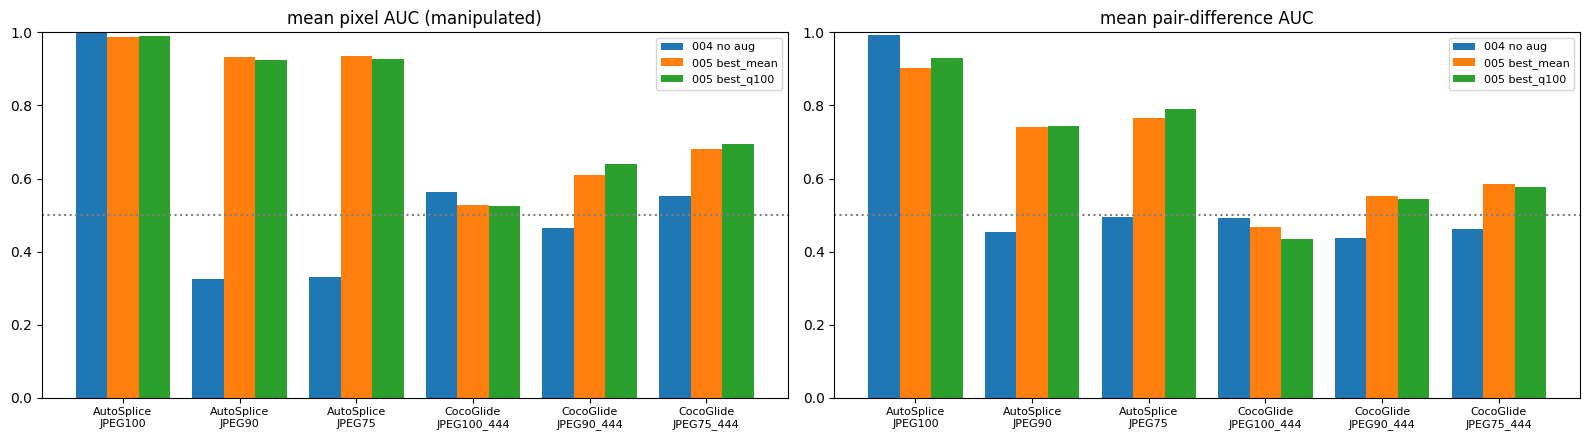

In [14]:
diagnostic_models = {"004 no aug": ref004_dir / "best.pt", "005 best_mean": run_root / "best_mean.pt",
                     "005 best_q100": run_root / "best_q100.pt"}
diagnostic_dir = run_root / "diagnostics"
diagnostic_dir.mkdir(parents=True, exist_ok=True)
manipulated_test = [r for r in test_records if r["kind"] == "manipulated"]
normal_test = {}
for record in test_records:
    if record["kind"] == "normal":
        key = (record["dataset"], record["original_id"], record["variant"] if record["dataset"] == "CocoGlide" else "original")
        normal_test[key] = record
groups = {}
for record in manipulated_test:
    groups.setdefault((record["dataset"], record["variant"]), []).append(record)
shuffled_mask_of = {}
for members in groups.values():
    members = sorted(members, key=lambda r: str(r["input_path"]))
    for index, record in enumerate(members):
        shuffled_mask_of[str(record["input_path"])] = members[(index + 1) % len(members)]["mask_path"]


def pixel_auc(score, mask, bins=1000):
    inside, outside = score[mask > 0], score[mask == 0]
    if inside.size == 0 or outside.size == 0:
        return np.nan
    low, high = float(score.min()), float(score.max())
    if high <= low:
        return 0.5
    edges = np.linspace(low, high, bins + 1)
    count_in = np.histogram(inside, edges)[0].astype(np.float64)
    count_out = np.histogram(outside, edges)[0].astype(np.float64)
    below_out = np.concatenate([[0.0], np.cumsum(count_out)[:-1]])
    return float((count_in * (below_out + 0.5 * count_out)).sum() / (inside.size * outside.size))


def f1_against(prediction, mask):
    tp, fp, fn, _ = confusion_counts(mask, prediction)
    return pixel_f1(tp, fp, fn)


def diagnose(name, checkpoint_path):
    out_path = diagnostic_dir / f"{name.replace(' ', '_')}.csv"
    marker = diagnostic_dir / f"{name.replace(' ', '_')}.json"
    checkpoint_hash = sha256(checkpoint_path)
    if marker.is_file() and json.loads(marker.read_text())["checkpoint_sha256"] == checkpoint_hash:
        print(f"[{name}] 저장된 진단 결과 사용")
        return pd.read_csv(out_path)
    model, checkpoint = load_model(checkpoint_path)
    rows, start = [], time.perf_counter()
    for index, record in enumerate(manipulated_test):
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        other = load_binary_mask(shuffled_mask_of[str(record["input_path"])], foreground_value=config["mask_foreground"])
        if other.shape != mask.shape:
            other = np.array(Image.fromarray(other).resize((mask.shape[1], mask.shape[0]), Image.NEAREST))
        row = dict(model=name, epoch=int(checkpoint["epoch"]), dataset=record["dataset"], variant=record["variant"],
                   image=Path(record["image_path"]).name, mask_ratio=float((mask > 0).mean()),
                   f1=f1_against(prediction, mask), f1_shuffled_mask=f1_against(prediction, other),
                   f1_all_ones=pixel_f1(int((mask > 0).sum()), int((mask == 0).sum()), 0),
                   pixel_auc=pixel_auc(probability, mask),
                   prob_inside=float(probability[mask > 0].mean()) if (mask > 0).any() else np.nan,
                   prob_outside=float(probability[mask == 0].mean()) if (mask == 0).any() else np.nan,
                   pair_prob_mean=np.nan, pair_diff_auc=np.nan)
        pair_key = (record["dataset"], record["original_id"], record["variant"] if record["dataset"] == "CocoGlide" else "original")
        pair = normal_test.get(pair_key)
        if pair is not None:
            pair_rgb, _ = load_pair(pair)
            if pair_rgb.shape == rgb.shape:
                pair_probability = predict_full(model, pair_rgb)
                row.update(pair_prob_mean=float(pair_probability.mean()),
                           pair_diff_auc=pixel_auc(probability - pair_probability, mask))
        rows.append(row)
        if (index + 1) % 500 == 0:
            print(f"[{name}] {index + 1}/{len(manipulated_test)} {time.perf_counter() - start:.0f}s")
    frame = pd.DataFrame(rows)
    frame.to_csv(out_path, index=False)
    marker.write_text(json.dumps(dict(checkpoint=str(checkpoint_path), checkpoint_sha256=checkpoint_hash,
                                      epoch=int(checkpoint["epoch"]), images=len(frame),
                                      seconds=time.perf_counter() - start), indent=1))
    print(f"[{name}] epoch {checkpoint['epoch']}, 조작 {len(frame)}장 진단 {time.perf_counter() - start:.0f}s")
    del model
    torch.cuda.empty_cache()
    return frame


diagnostics = pd.concat([diagnose(name, path) for name, path in diagnostic_models.items()], ignore_index=True)
diagnostic_summary = diagnostics.groupby(["dataset", "variant", "model"], sort=False).agg(
    images=("image", "size"), f1=("f1", "mean"), f1_shuffled_mask=("f1_shuffled_mask", "mean"),
    f1_all_ones=("f1_all_ones", "mean"), pixel_auc=("pixel_auc", "mean"),
    pair_diff_auc=("pair_diff_auc", "mean"), pairs=("pair_diff_auc", "count"),
    prob_inside=("prob_inside", "mean"), prob_outside=("prob_outside", "mean"), pair_prob_mean=("pair_prob_mean", "mean"))
diagnostic_summary["f1_gain_over_shuffled"] = diagnostic_summary.f1 - diagnostic_summary.f1_shuffled_mask
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_rows", None, "display.width", 250):
    display(diagnostic_summary)

figure, axes = plt.subplots(1, 2, figsize=(16, 4.5))
labels = [f"{d}\n{v}" for d, v in groups]
for offset, name in enumerate(diagnostic_models):
    values = [diagnostics[(diagnostics.model == name) & (diagnostics.dataset == d) & (diagnostics.variant == v)] for d, v in groups]
    x_positions = np.arange(len(groups)) + (offset - 1) * 0.27
    axes[0].bar(x_positions, [g.pixel_auc.mean() for g in values], width=0.27, label=name)
    axes[1].bar(x_positions, [g.pair_diff_auc.mean() for g in values], width=0.27, label=name)
for axis, title in zip(axes, ["mean pixel AUC (manipulated)", "mean pair-difference AUC"]):
    axis.axhline(0.5, color="gray", linestyle=":")
    axis.set_xticks(np.arange(len(groups)), labels, fontsize=8)
    axis.set_ylim(0, 1)
    axis.set_title(title)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()